# DATA CLEANING AND MERGING

In [1]:
import pandas as pd 
hotels = pd.read_csv("/kaggle/input/hoteldataset/hotels.csv") 
reviews = pd.read_csv("/kaggle/input/hoteldataset/reviews.csv") 
users = pd.read_csv("/kaggle/input/hoteldataset/users.csv")

In [2]:
# Check missing values in each dataset
print(hotels.isnull().sum())
print(reviews.isnull().sum())
print(users.isnull().sum())

hotel_id                0
hotel_name              0
city                    0
country                 0
star_rating             0
lat                     0
lon                     0
cleanliness_base        0
comfort_base            0
facilities_base         0
location_base           0
staff_base              0
value_for_money_base    0
dtype: int64
review_id                0
user_id                  0
hotel_id                 0
review_date              0
score_overall            0
score_cleanliness        0
score_comfort            0
score_facilities         0
score_location           0
score_staff              0
score_value_for_money    0
review_text              0
dtype: int64
user_id           0
user_gender       0
country           0
age_group         0
traveller_type    0
join_date         0
dtype: int64


In [3]:
# remove duplicates
hotels.drop_duplicates(inplace=True)
reviews.drop_duplicates(inplace=True)
users.drop_duplicates(inplace=True)


In [4]:
#remove unnecessary columns
hotels = hotels.drop(columns=['lat', 'lon'])
reviews = reviews.drop(columns=['review_id', 'review_date', 'review_text'])
users = users.drop(columns=['join_date'])

In [5]:
# merge reviews with hotels using hotel id
merged_df = reviews.merge(hotels, on='hotel_id', how='left')

# merge the result with users using user id
merged_df = merged_df.merge(users, on='user_id', how='left')

merged_df.head()


,user_id,hotel_id,score_overall,score_cleanliness,score_comfort,score_facilities,score_location,score_staff,score_value_for_money,hotel_name,...,cleanliness_base,comfort_base,facilities_base,location_base,staff_base,value_for_money_base,user_gender,country_y,age_group,traveller_type
0,1600,1,8.7,8.6,8.7,8.5,9.0,8.8,8.7,The Azure Tower,...,9.1,8.8,8.9,9.5,8.6,8.0,Female,New Zealand,25-34,Solo
1,432,4,9.1,10.0,9.1,9.0,8.6,9.4,8.6,Kyo-to Grand,...,9.6,9.0,9.3,8.5,9.5,8.2,Female,United Kingdom,35-44,Couple
2,186,18,8.8,9.7,8.8,8.3,8.7,8.1,8.6,Nile Grandeur,...,8.8,8.7,8.6,9.1,8.7,8.4,Female,Spain,55+,Couple
3,1403,19,8.9,9.0,8.8,8.5,9.6,9.1,8.3,Gaudi's Retreat,...,9.2,9.1,8.9,9.7,9.0,8.8,Female,United Kingdom,35-44,Business
4,1723,17,9.1,8.9,9.5,9.3,8.3,9.4,8.9,Kremlin Suites,...,9.1,9.3,9.0,9.0,9.1,8.6,Male,Australia,45-54,Family


In [6]:
merged_df.shape #50000


(50000, 23)

In [7]:
import os
os.makedirs("/kaggle/working/data", exist_ok=True)
merged_df.to_csv("/kaggle/working/data/merged_hotel_data.csv", index=False)


# NEW COUNTRY_GROUP COLUMN

In [8]:
merged_df['country_y'].unique()

array(['New Zealand', 'United Kingdom', 'Spain', 'Australia',
       'United States', 'China', 'United Arab Emirates', 'Canada',
       'Brazil', 'Argentina', 'Germany', 'Netherlands', 'Russia',
       'South Korea', 'Japan', 'Italy', 'India', 'South Africa',
       'Nigeria', 'Thailand', 'Turkey', 'France', 'Singapore', 'Mexico',
       'Egypt'], dtype=object)

In [9]:
# new country groups column
country_map = {
    'United States': 'North_America',
    'Canada': 'North_America',
    'Germany': 'Western_Europe',
    'France': 'Western_Europe',
    'United Kingdom': 'Western_Europe',
    'Netherlands': 'Western_Europe',
    'Spain': 'Western_Europe',
    'Italy': 'Western_Europe',
    'Russia': 'Eastern_Europe',
    'China': 'East_Asia',
    'Japan': 'East_Asia',
    'South Korea': 'East_Asia',
    'Thailand': 'Southeast_Asia',
    'Singapore': 'Southeast_Asia',
    'United Arab Emirates': 'Middle_East',
    'Turkey': 'Middle_East',
    'Egypt': 'Africa',
    'Nigeria': 'Africa',
    'South Africa': 'Africa',
    'Australia': 'Oceania',
    'New Zealand': 'Oceania',
    'Brazil': 'South_America',
    'Argentina': 'South_America',
    'India': 'South_Asia',
    'Mexico': 'North_America_Mexico'
}

# Create the country_group column
merged_df['country_group'] = merged_df['country_y'].map(country_map)

# Check the new column
merged_df[['country_y', 'country_group']].head()


,country_y,country_group
0,New Zealand,Oceania
1,United Kingdom,Western_Europe
2,Spain,Western_Europe
3,United Kingdom,Western_Europe
4,Australia,Oceania


In [10]:
merged_df.head()

,user_id,hotel_id,score_overall,score_cleanliness,score_comfort,score_facilities,score_location,score_staff,score_value_for_money,hotel_name,...,comfort_base,facilities_base,location_base,staff_base,value_for_money_base,user_gender,country_y,age_group,traveller_type,country_group
0,1600,1,8.7,8.6,8.7,8.5,9.0,8.8,8.7,The Azure Tower,...,8.8,8.9,9.5,8.6,8.0,Female,New Zealand,25-34,Solo,Oceania
1,432,4,9.1,10.0,9.1,9.0,8.6,9.4,8.6,Kyo-to Grand,...,9.0,9.3,8.5,9.5,8.2,Female,United Kingdom,35-44,Couple,Western_Europe
2,186,18,8.8,9.7,8.8,8.3,8.7,8.1,8.6,Nile Grandeur,...,8.7,8.6,9.1,8.7,8.4,Female,Spain,55+,Couple,Western_Europe
3,1403,19,8.9,9.0,8.8,8.5,9.6,9.1,8.3,Gaudi's Retreat,...,9.1,8.9,9.7,9.0,8.8,Female,United Kingdom,35-44,Business,Western_Europe
4,1723,17,9.1,8.9,9.5,9.3,8.3,9.4,8.9,Kremlin Suites,...,9.3,9.0,9.0,9.1,8.6,Male,Australia,45-54,Family,Oceania


# Question 1: Which city is best for each traveler type?

In [11]:
print("different travel types:" , merged_df['traveller_type'].unique())
print("-------------------------")
print("different cities:" ,merged_df['city'].unique())

different travel types: ['Solo' 'Couple' 'Business' 'Family']
-------------------------
different cities: ['New York' 'Tokyo' 'Cairo' 'Barcelona' 'Moscow' 'Sydney' 'Buenos Aires'
 'Singapore' 'Mumbai' 'Cape Town' 'Berlin' 'Wellington' 'Paris' 'Shanghai'
 'Lagos' 'London' 'Bangkok' 'Istanbul' 'Mexico City' 'Toronto' 'Dubai'
 'Seoul' 'Amsterdam' 'Rome' 'Rio de Janeiro']


In [12]:
#group reviews by traveler type and city
#calculate the average score overall score for each group
#remove the grouping index back to normal index
city_scores = merged_df.groupby(['traveller_type', 'city'])['score_overall'].mean().reset_index()
city_scores.head()


,traveller_type,city,score_overall
0,Business,Amsterdam,8.964348
1,Business,Bangkok,8.886265
2,Business,Barcelona,8.904545
3,Business,Berlin,8.868122
4,Business,Buenos Aires,8.690000


In [13]:
city_scores.tail()

,traveller_type,city,score_overall
95,Solo,Singapore,9.058916
96,Solo,Sydney,8.914286
97,Solo,Tokyo,8.973317
98,Solo,Toronto,9.045980
99,Solo,Wellington,9.027803


In [14]:
#find the row with the highest score for each traveler type.
best_city_per_type = city_scores.loc[city_scores.groupby('traveller_type')['score_overall'].idxmax()]

In [15]:
best_city_per_type

,traveller_type,city,score_overall
7,Business,Dubai,8.965668
25,Couple,Amsterdam,9.096989
57,Family,Dubai,9.214381
75,Solo,Amsterdam,9.108454


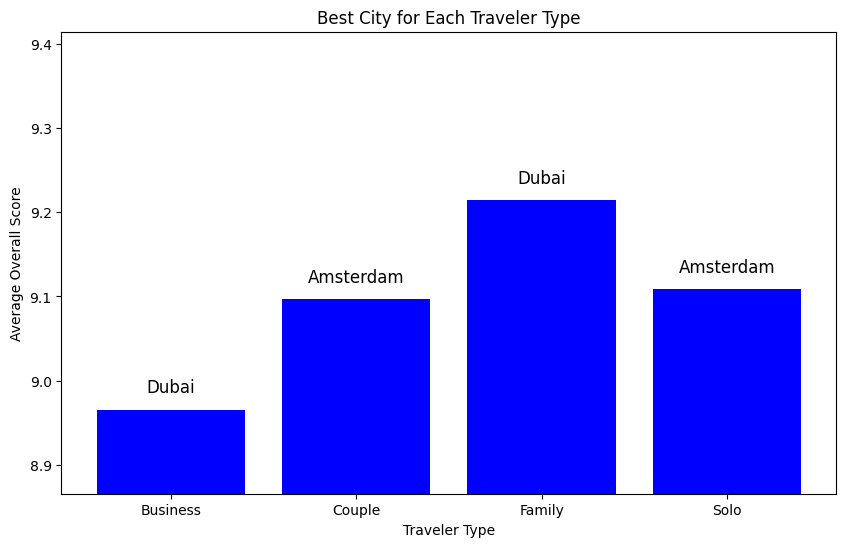

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(best_city_per_type['traveller_type'], 
        best_city_per_type['score_overall'], 
        color='blue')


for i, (traveler, city, score) in enumerate(zip(best_city_per_type['traveller_type'], 
                                                best_city_per_type['city'], 
                                                best_city_per_type['score_overall'])):
    plt.text(i, score + 0.02, city, ha='center', fontsize=12)

plt.xlabel("Traveler Type")
plt.ylabel("Average Overall Score")
plt.title("Best City for Each Traveler Type")
plt.ylim(best_city_per_type['score_overall'].min() - 0.1, 
         best_city_per_type['score_overall'].max() + 0.2)
plt.show()


# Question 2: Top 3 Countries with Best Value-for-Money per Age Group

In [17]:
print(merged_df['age_group'].unique())

['25-34' '35-44' '55+' '45-54' '18-24']


In [18]:
#group age group with country
#get the average score value for money
#reset index
avg_value = merged_df.groupby(['age_group', 'country_y'])['score_value_for_money'].mean().reset_index()

In [19]:
#sort age group ascending but score value for money in descending
#get top 3
avg_value = avg_value.sort_values(['age_group', 'score_value_for_money'], ascending=[True, False])
top3 = avg_value.groupby('age_group').head(3) 
top3

,age_group,country_y,score_value_for_money
5,18-24,Egypt,9.007317
19,18-24,Spain,8.768132
0,18-24,Argentina,8.689000
44,25-34,Spain,8.733259
43,25-34,South Korea,8.632800
37,25-34,Netherlands,8.542157
66,35-44,Singapore,8.795385
50,35-44,Argentina,8.696519
63,35-44,New Zealand,8.641079
94,45-54,Turkey,8.641778


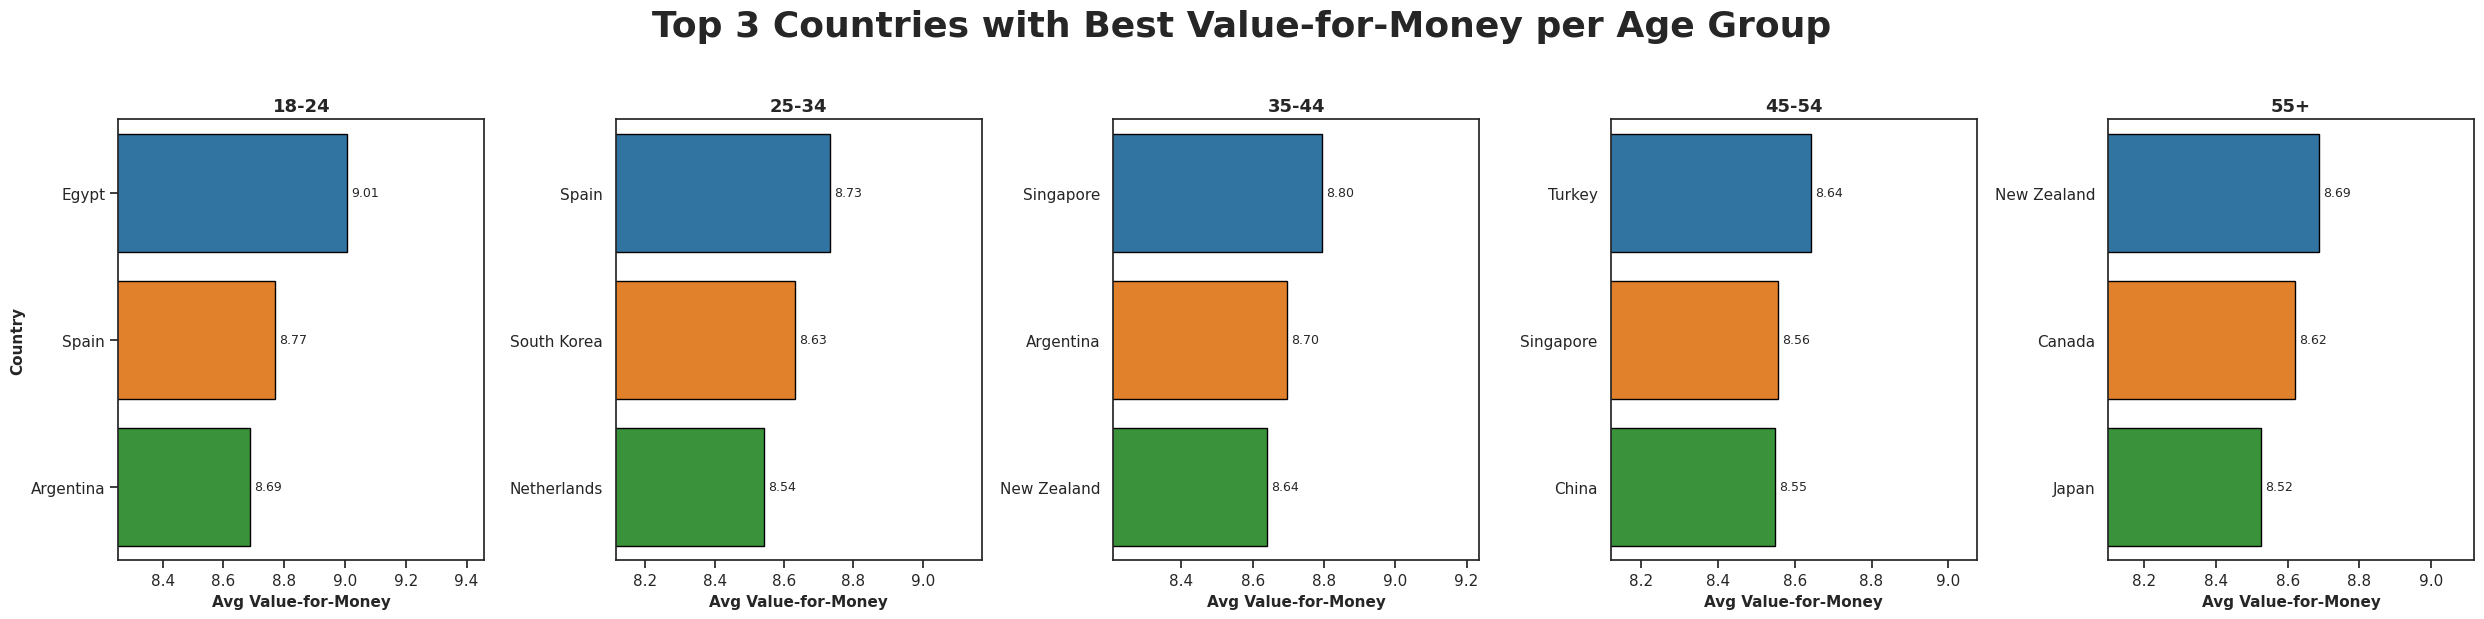

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set(style="ticks") 


age_groups = top3['age_group'].unique()

# create one plot for each age group
plt.figure(figsize=(5 * len(age_groups), 6))

for i, group in enumerate(age_groups, start=1):
    # filter only this age group
    group_data = top3[top3['age_group'] == group].sort_values(
        by='score_value_for_money', ascending=False
    )

    # a subplot
    plt.subplot(1, len(age_groups), i)


    sns.barplot(
        data=group_data,
        y='country_y',
        x='score_value_for_money',
        palette='tab10',  # bright colors
        edgecolor='black'
    )


    plt.title(f'{group}', fontsize=13, fontweight='bold')
    plt.xlabel('Avg Value-for-Money', fontsize=11, fontweight='bold')

    # only show y label on first plot
    if i == 1:
        plt.ylabel('Country', fontsize=11 , fontweight='bold')
    else:
        plt.ylabel('')
        plt.tick_params(axis='y', left=False)

    # add numbers on bars
    for container in plt.gca().containers:
        plt.bar_label(container, fmt='%.2f', fontsize=9, padding=3)

    # zoom in on the range to exaggerate differences
    min_score = group_data['score_value_for_money'].min()
    max_score = group_data['score_value_for_money'].max()
    plt.xlim(min_score * 0.95, max_score * 1.05)

plt.suptitle('Top 3 Countries with Best Value-for-Money per Age Group', 
             fontsize=26, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()


# Predictive Modeling Task

In [21]:
#features and target
features = [
    'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 
    'score_staff', 'score_value_for_money',  'age_group', 'user_gender', 'traveller_type',
    'star_rating', 'cleanliness_base', 'comfort_base', 'facilities_base'
]

X = merged_df[features]
y = merged_df['country_group']

#convert non numerical columns to numbers
X = pd.get_dummies(X, ['age_group', 'user_gender', 'traveller_type'], drop_first=True)

In [22]:
#split dataset 
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,)


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth= None,
    min_samples_split=3,
    class_weight= 'balanced', 
    min_samples_leaf=2,
    random_state=42
)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

Model Performance Summary
Accuracy: 0.2554
Macro Precision: 0.1383
Macro Recall: 0.1320
Macro F1-score: 0.1341
Weighted Precision: 0.2382
Weighted Recall: 0.2554
Weighted F1-score: 0.2455

 Classification Report:

                      precision    recall  f1-score   support

              Africa       0.06      0.05      0.05       305
           East_Asia       0.22      0.22      0.22      1618
      Eastern_Europe       0.07      0.06      0.06       264
         Middle_East       0.10      0.08      0.09       469
       North_America       0.25      0.24      0.25      1935
North_America_Mexico       0.08      0.06      0.07       243
             Oceania       0.12      0.11      0.11       548
       South_America       0.10      0.08      0.09       631
          South_Asia       0.07      0.05      0.06       335
      Southeast_Asia       0.07      0.06      0.06       259
      Western_Europe       0.37      0.44      0.40      3393

            accuracy                    

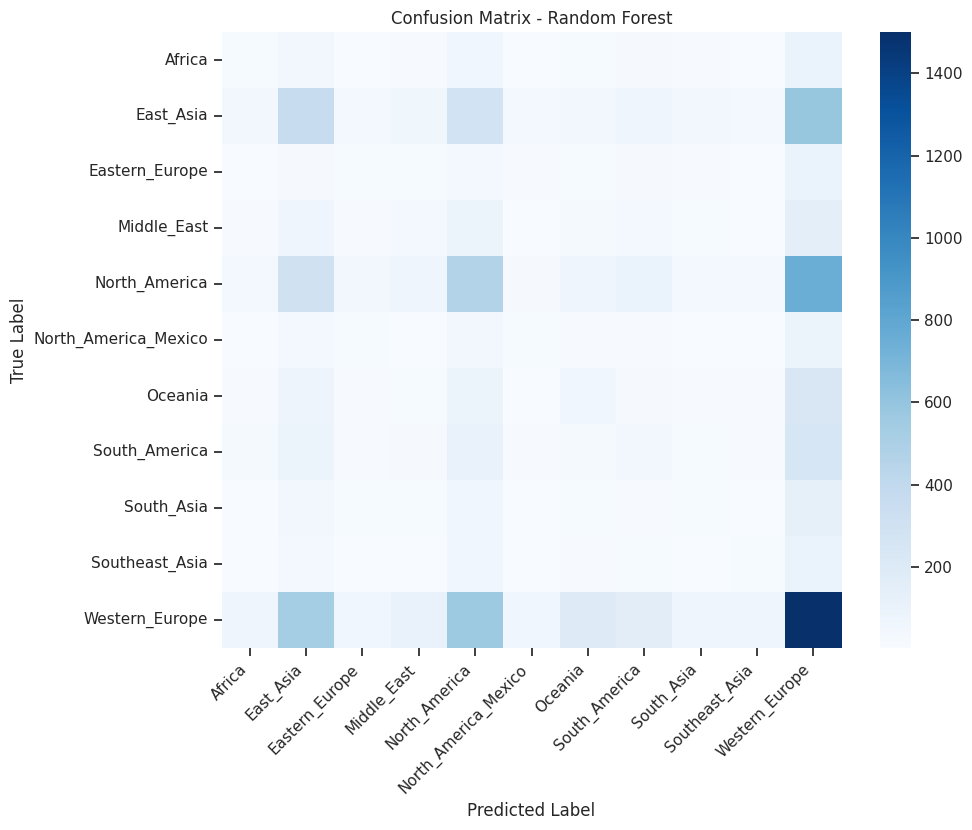

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# metrics
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
precision_weighted = precision_score(y_test, y_pred, average='weighted')
recall_weighted = recall_score(y_test, y_pred, average='weighted')
f1_weighted = f1_score(y_test, y_pred, average='weighted')


print("Model Performance Summary")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro Precision: {precision_macro:.4f}")
print(f"Macro Recall: {recall_macro:.4f}")
print(f"Macro F1-score: {f1_macro:.4f}")
print(f"Weighted Precision: {precision_weighted:.4f}")
print(f"Weighted Recall: {recall_weighted:.4f}")
print(f"Weighted F1-score: {f1_weighted:.4f}")

print("\n Classification Report:\n")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
labels = sorted(list(set(y_test)))  # get all class names in order

plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues', 
            xticklabels=labels, yticklabels=labels)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()

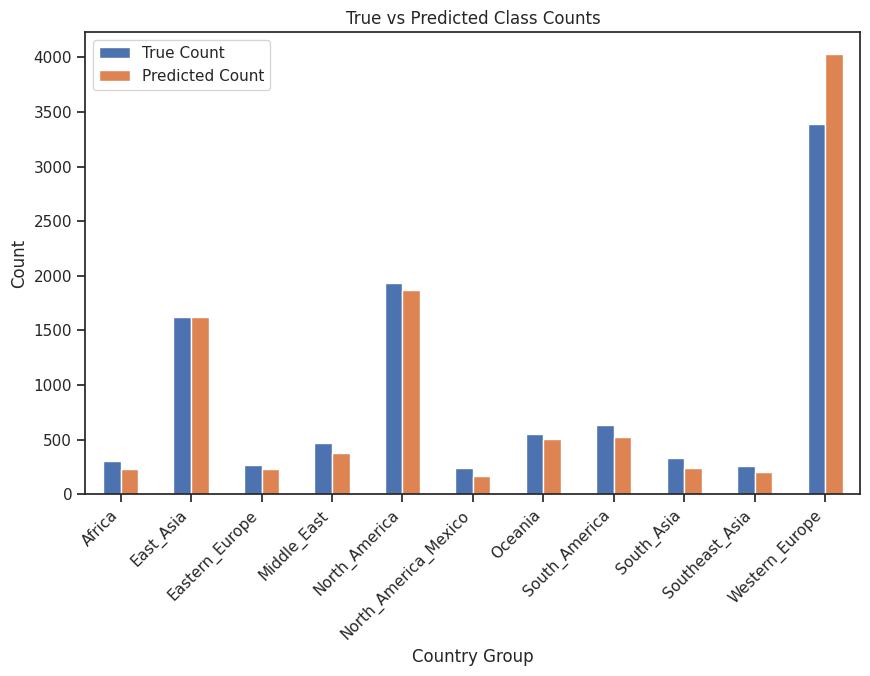

In [25]:
# True vs Predicted comparison
true_counts = pd.Series(y_test).value_counts().sort_index()
pred_counts = pd.Series(y_pred).value_counts().sort_index()

comparison_df = pd.DataFrame({
    'True Count': true_counts,
    'Predicted Count': pred_counts
}).fillna(0)

comparison_df.plot(kind='bar', figsize=(10,6))
plt.title("True vs Predicted Class Counts")
plt.xlabel("Country Group")
plt.ylabel("Count")
plt.xticks(rotation=45, ha='right')
plt.show()


# XAI

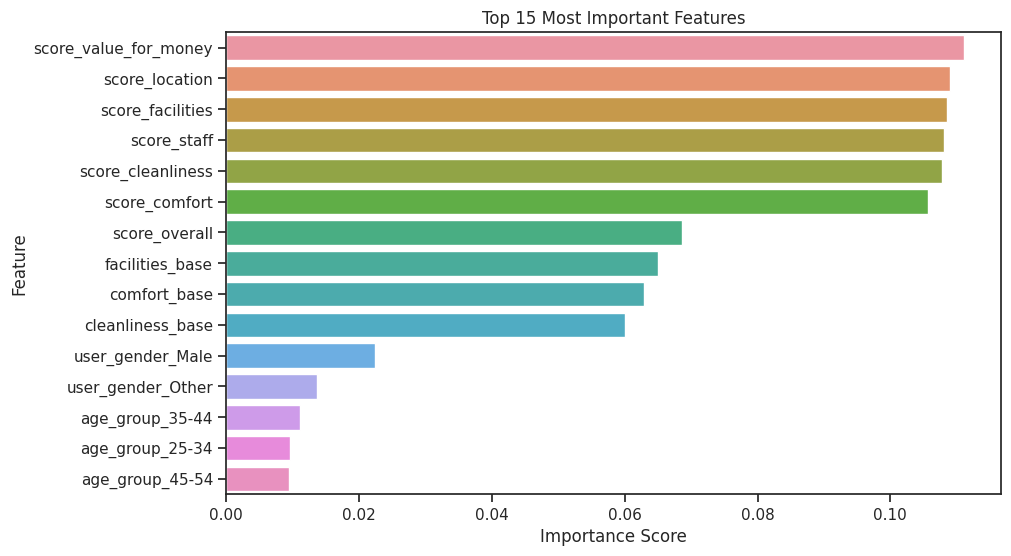

In [26]:
# Feature Importance Graph
import pandas as pd

feature_importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=feature_importances.head(15))
plt.title("Top 15 Most Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()


In [27]:
!pip install -U shap


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 16.1 MB/s eta 0:00:00
  Attempting uninstall: slicer
    Found existing installation: slicer 0.0.7
    Uninstalling slicer-0.0.7:
      Successfully uninstalled slicer-0.0.7
  Attempting uninstall: shap
    Found existing installation: shap 0.44.1
    Uninstalling shap-0.44.1:
      Successfully uninstalled shap-0.44.1
